# Code tutorial connectomics I - Computational Neuroscience

This tutorial introduces basic concepts about graph theory in connectomics and recreates the Rich Club analysis from Towlson et al., 2013, Journal of Neuroscience

## C1 Imports and installation

In [32]:
# Clone the course repository
!git clone https://github.com/ChristianPritz/unito_computational_neuroscience

# Move into the session directory
%cd unito_connectomics_i

# Install only the packages needed for this session
%pip install -U navis plotly ipywidgets jupyterlab_widgets jupyterlab nbformat networkx neuprint-python matplotlib pandas numpy seaborn joblib

#handle all the imports
import os
import sys
import pandas as pd
import networkx as nx
from networkx.algorithms import community
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
sys.path.append(os.getcwd()+'/code')
from connectomics_functions import *

[Errno 2] No such file or directory: 'unito_connectomics_i'
/home/wormulon/models/unito_computational_neuroscience/connectomics_i


## C2 Exploring basic concepts in graph theory for connectomics

In this section, we will explore some fundamental concepts of graph theory applied to connectomics.

We will start by loading an adjacency matrix, visualising the corresponding graph, and examining some basic network statistics:

- **In-degree and out-degree:** quantify the number of incoming and outgoing connections for each neuron.
- **Shortest path length:** measures the minimum number of connections needed to travel from one neuron to another.
- **Clustering coefficient:** measures how strongly interconnected a neuron's neighbours are. We can calculate it for each neuron and then compute the average across the network:

$$
C_i = \frac{2E_i}{k_i(k_i-1)}, \qquad
C = \frac{1}{N}\sum_{i=1}^{N} C_i
$$

- **Small-world coefficient:** compares the clustering coefficient and average shortest path length of the observed network with those of an equivalent random network:

$$
\sigma = \frac{C/C_{\mathrm{rand}}}{L/L_{\mathrm{rand}}}
$$

#### Abbreviations and notation

- $C_i$: clustering coefficient of neuron $i$.
- $C$: average clustering coefficient of the network.
- $E_i$: number of connections between the neighbours of neuron $i$.
- $k_i$: degree of neuron $i$.
- $N$: total number of neurons in the network.
- $L$: average shortest path length of the observed network.
- $C_{\mathrm{rand}}$: average clustering coefficient of random networks.
- $L_{\mathrm{rand}}$: average shortest path length of random networks.
- $\sigma$: small-world coefficient.
- $T_i$ = number of triangles (closed triplets) involving node \(i\).

Full formula of $C_i$ using the adjacency matrix notation :
$C_i = \frac{2\sum_{j,h} A_{ij}A_{ih}A_{jh}}{k_i(k_i-1)}$


#### Let's load an adjacency matrix of a small network

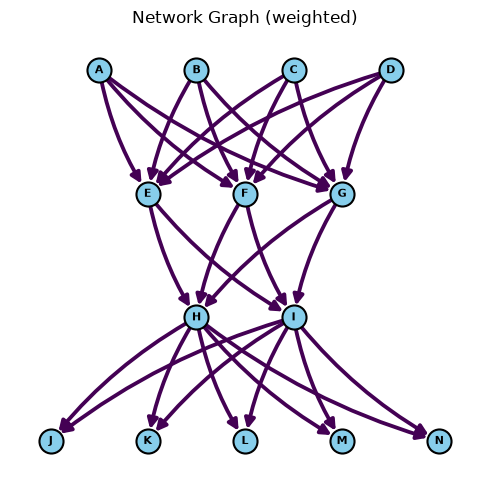

/home/wormulon/models/unito_computational_neuroscience/connectomics_i/code/connectomics_functions.py:452: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


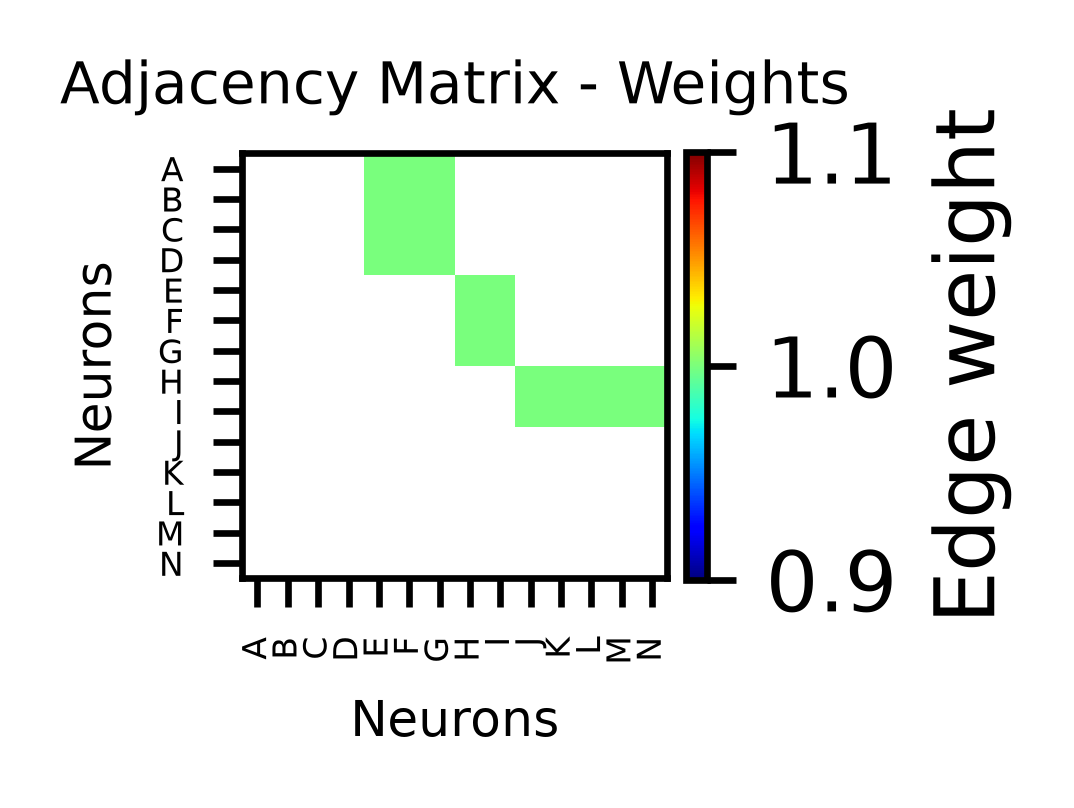


                        NETWORK STATISTICS                        
  Number of neurons:                                        14
  Total number of connections:                              28

------------------------------------------------------------------
  DEGREE STATISTICS
------------------------------------------------------------------
  Average in-degree:                                      2.00
  Average out-degree:                                     2.00

------------------------------------------------------------------
  PATH LENGTH AND REACHABILITY
------------------------------------------------------------------
  Average directed shortest path length:                  1.89
  Reachability:                                          39.01 %

------------------------------------------------------------------
  CLUSTERING AND SMALL-WORLDNESS
------------------------------------------------------------------
  Average clustering coefficient:                         0.00


In [33]:
# loading the adjacency matrix from a csv file in the data folder
A_machine, nodes = load_adjacency_matrix(os.getcwd()+"/data/testConn.csv")
#instantiating the the graph and renaming the neurons 
G_machine = nx.from_numpy_array(A_machine, create_using=nx.DiGraph)
G_machine = nx.relabel_nodes(G_machine, dict(enumerate(nodes)))#

# this variable assigns the position of the neurons in our example graphs
positions = {"A": [0,0],
             "B": [1,0],
             "C": [2,0],
             "D": [3,0],
             "E": [0.5,-1],
             "F": [1.5,-1],
             "G": [2.5,-1],
             "H": [1,-2],
             "I": [2,-2],
             "J": [-0.5,-3],
             "K": [0.5,-3],
             "L": [1.5,-3],
             "M": [2.5,-3],
             "N": [3.5,-3],}

#Let us plot the graph 
plot_network(G_machine,positions=positions,show_legend=False)
#Adjacency matrix
plot_adjacency_matrix(G_machine,sort_nodes=False, figsize=(1,1))
#Basic statistics 
stats_machine = basic_stats(G_machine)

## C3 This doesn't look like a graph from biological nervous system. 
Let's rework the graph  so that the information can flow bi-directionally. Try to edit it until the reachability is 100% and graph is fully connected. 

### However, do not spend more than 28 connections!

Did you achieve a fully connected layout? What kind of network structure did emerge? 

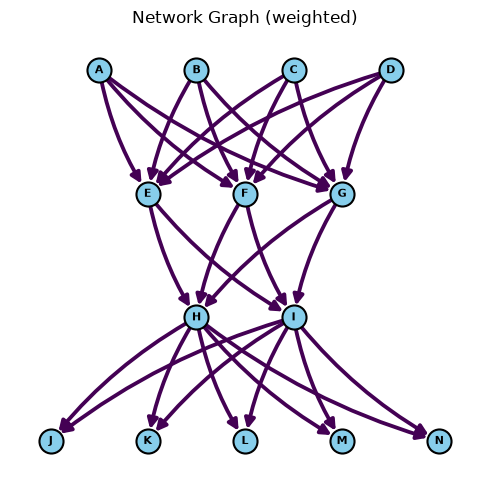

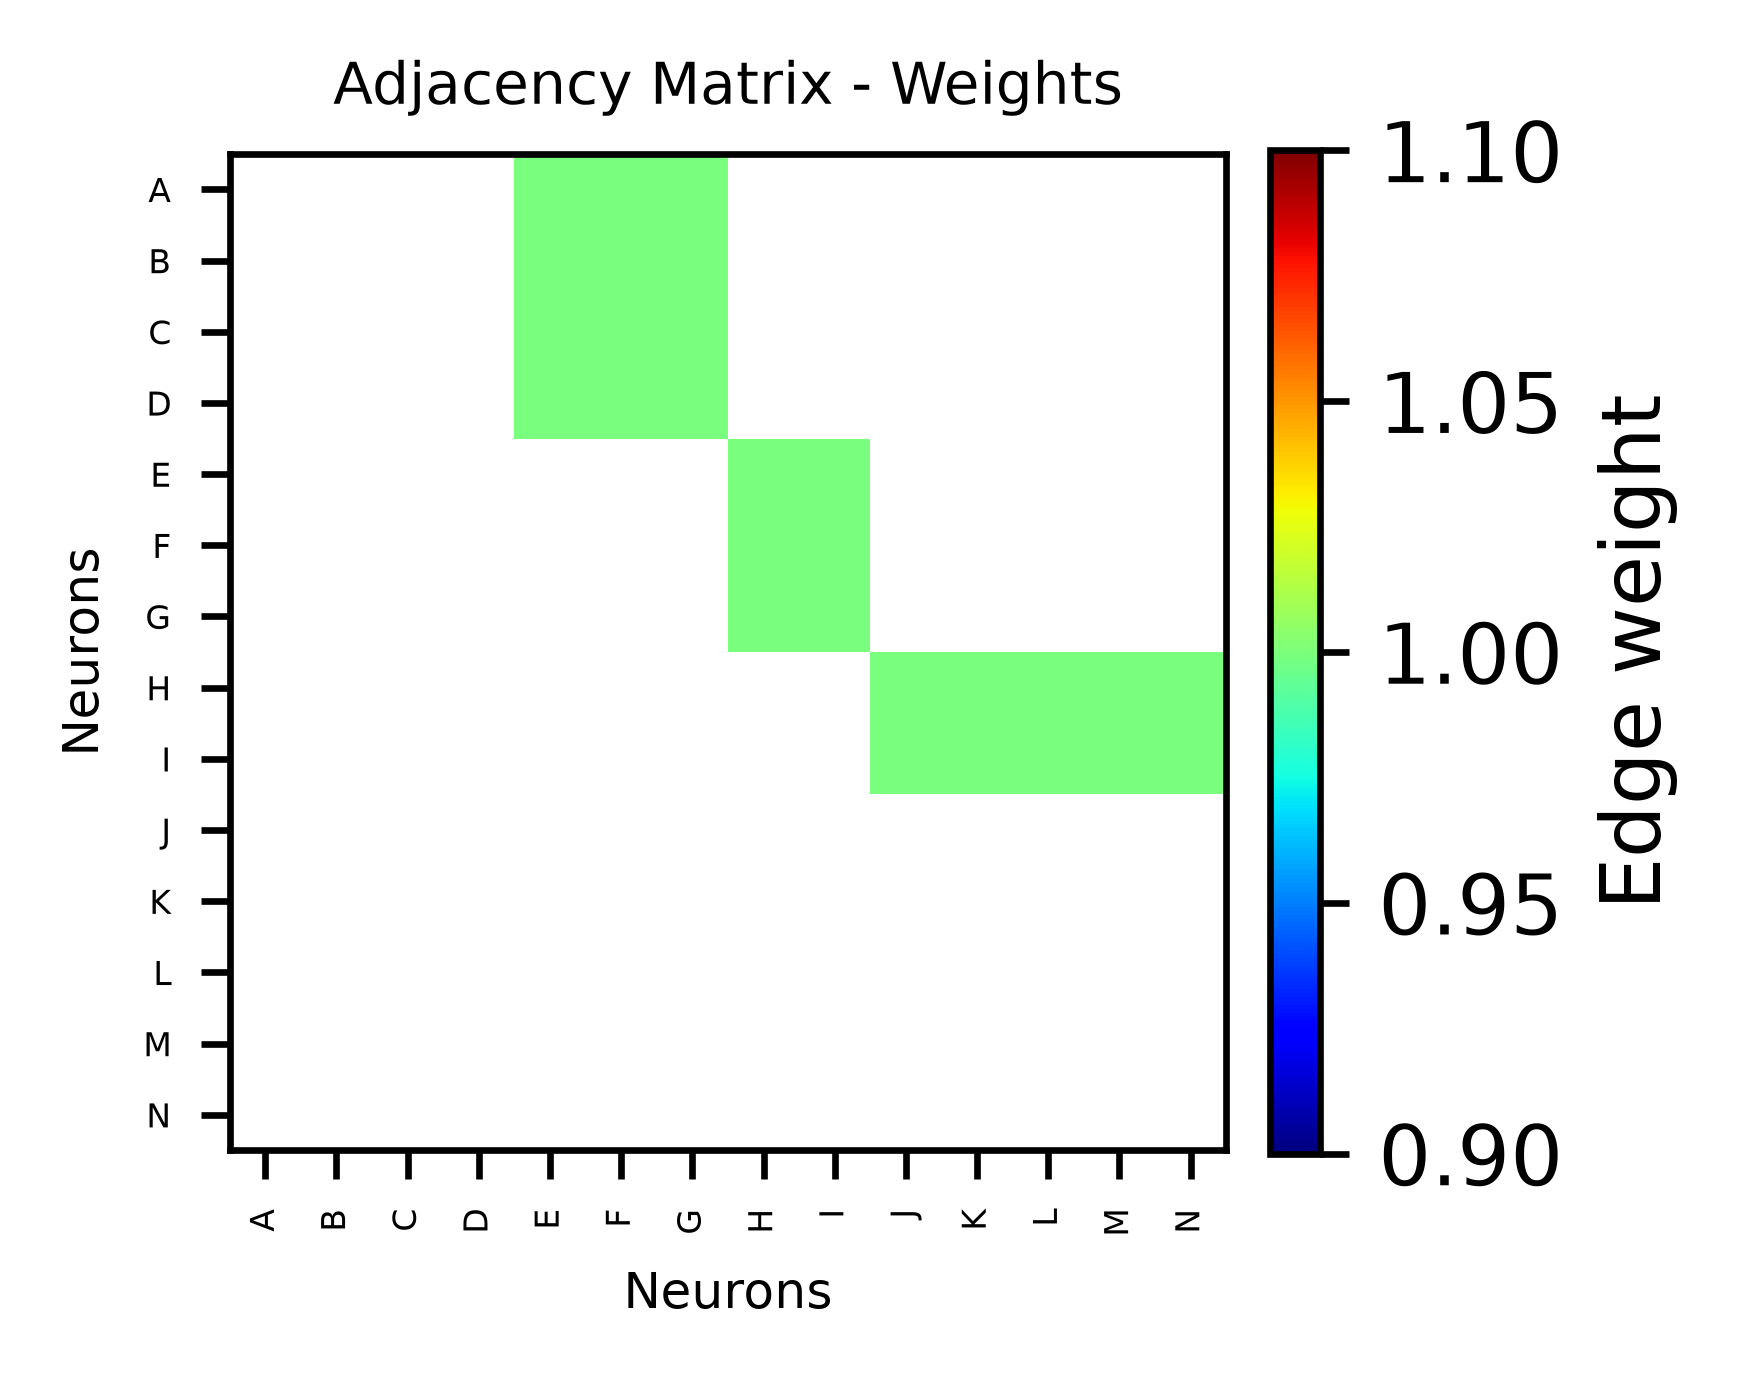


                        NETWORK STATISTICS                        
  Number of neurons:                                        14
  Total number of connections:                              28

------------------------------------------------------------------
  DEGREE STATISTICS
------------------------------------------------------------------
  Average in-degree:                                      2.00
  Average out-degree:                                     2.00

------------------------------------------------------------------
  PATH LENGTH AND REACHABILITY
------------------------------------------------------------------
  Average directed shortest path length:                  1.89
  Reachability:                                          39.01 %

------------------------------------------------------------------
  CLUSTERING AND SMALL-WORLDNESS
------------------------------------------------------------------
  Average clustering coefficient:                         0.00


In [36]:

                #   A   B   C   D    E   F  G   H   I   J   K   L   M   N
A_edit = np.array([[0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0.],   #A
                   [0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0.],   #B
                   [0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0.],   #C
                   [0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0.],   #D
                   [0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0.],   #E
                   [0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0.],   #F
                   [0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0.],   #G
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1.],   #H
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1.],   #I
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],   #J
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],   #K
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],   #L
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],   #M
                   [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])  #N

#Checking if you were adhering to the constraints 
if np.sum(A_edit) > 28:
    print("\033[91m###############################################################################\033[0m")
    print("\033[91mYou have used more than 28 connections! Please reduce the number of edges!\033[0m")
    print("\033[91m###############################################################################\033[0m")

#Instantiating the graph 
G_edit = nx.from_numpy_array(A_edit, create_using=nx.DiGraph)
G_edit = nx.relabel_nodes(G_edit, dict(enumerate(nodes)))
#Plotting the network
plot_network(G_edit,positions=positions,show_legend=False)
#Plotting the adjacency matrix 
plot_adjacency_matrix(G_edit,sort_nodes=False, figsize=(3,3))
#checking statistics 
stats_edit = basic_stats(G_edit)


# Teacher cell

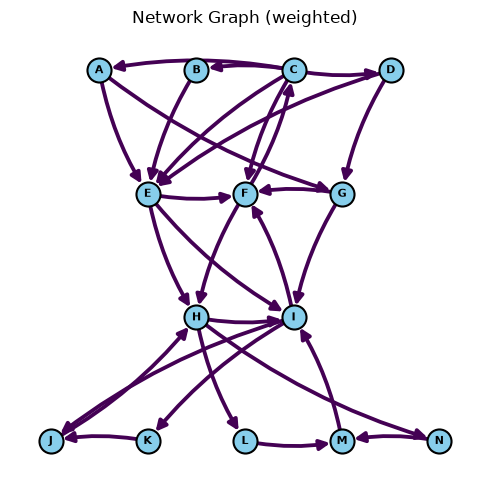

/home/wormulon/models/unito_computational_neuroscience/connectomics_i/code/connectomics_functions.py:452: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


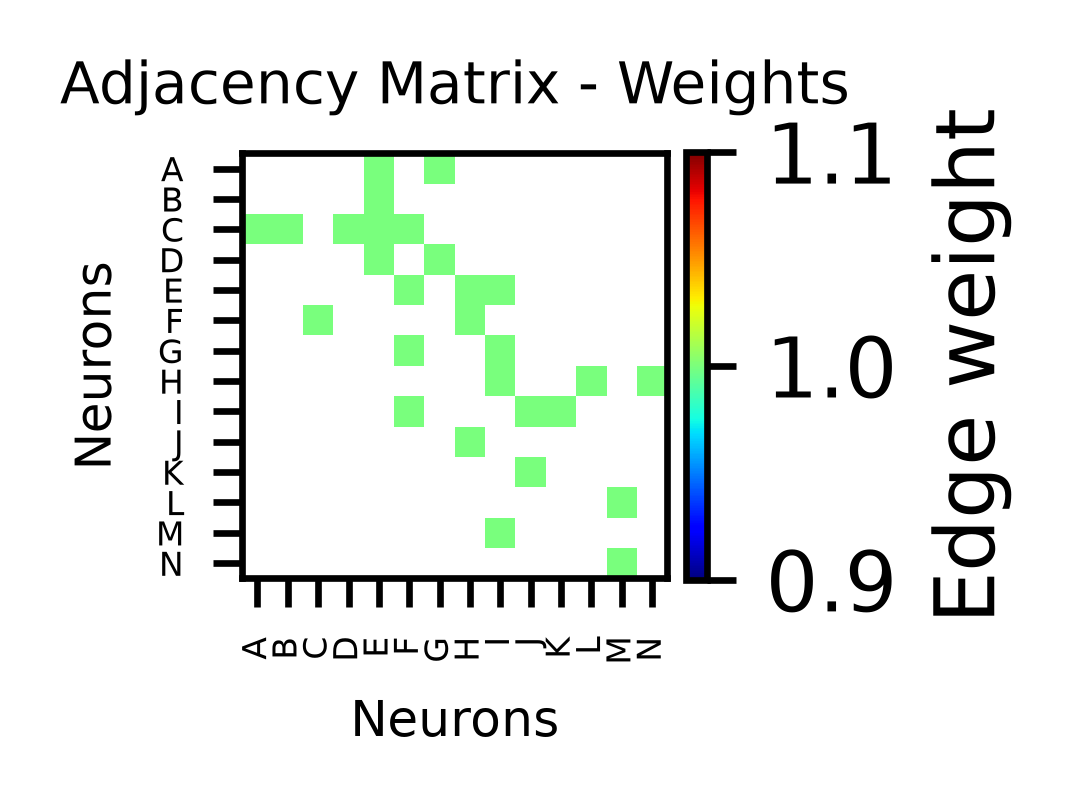


                        NETWORK STATISTICS                        
  Number of neurons:                                        14
  Total number of connections:                              28

------------------------------------------------------------------
  DEGREE STATISTICS
------------------------------------------------------------------
  Average in-degree:                                      2.00
  Average out-degree:                                     2.00

------------------------------------------------------------------
  PATH LENGTH AND REACHABILITY
------------------------------------------------------------------
  Average directed shortest path length:                  2.96
  Reachability:                                         100.00 %

------------------------------------------------------------------
  CLUSTERING AND SMALL-WORLDNESS
------------------------------------------------------------------
  Average clustering coefficient:                         0.38


In [29]:
# loading the adjacency matrix from a csv file in the data folder
A_bio, nodes = load_adjacency_matrix(os.getcwd()+"/data/testConn2.csv")
#instantiating the the graph and renaming the neurons 
G_bio = nx.from_numpy_array(A_bio, create_using=nx.DiGraph)
G_bio = nx.relabel_nodes(G_bio, dict(enumerate(nodes)))

#Let us plot the graph 
plot_network(G_bio,positions=positions,show_legend=False)
plot_adjacency_matrix(G_bio,sort_nodes=False, figsize=(1,1))
stats_bio = basic_stats(G_bio)

## C4 "Write" your own code 

Please prompt your favorite AI tool to provide you with a pasteable function for jupyter that calcluates:

* average in and out degrees,
* average shortest path length,
* Reachability of the network (how many neurons are reachable). 
* clustering coefficient
* Small-world coefficient

It should use python's networkx module, be called "basic_stats_custom" and take a networkx graph object as input. 
The above mentioned metrics should be shown as clean print statements and returned to the user. 

Then past the definition of the function in the cell below and run the cell. 



## C5 Let's see how the output's line up. 

In [ ]:
stats_edit = basic_stats(G_edit)
stats_edit = basic_stats_custom(G_edit)

## Teacher cell

Let's see what a fully connected network would look like. Wiring without constraints

In [ ]:

# hubs and sparcity are a consequence of the energy constraints set by the need for survival. 
A_full = np.ones_like(A_edit)
A_full[np.arange(0,A_full.shape[0]),np.arange(0,A_full.shape[1])] = 0 #removing self-loops
G_full = nx.from_numpy_array(A_full, create_using=nx.DiGraph)
G_full = nx.relabel_nodes(G_full, dict(enumerate(nodes)))

#plot appearance settings 
settings = {
        "node_size": 300,
        "node_color": "skyblue",
        "node_edgecolor": "black",
        "node_linewidth": 1,
        "node_alpha": 1.0,

        "edge_alpha": 0.8,
        "edge_curvature": 0.1,
        "edge_style": "solid",
        "arrow_size": 15,
        "arrow_style": "-|>",

        "edge_color_mode": "weight",
        "edge_color": "gray",

        "label_font_size": 8,
        "label_font_color": "black",
        "label_font_weight": "bold",

        "title": "Network Graph (weighted)",
        "title_font_size": 12
    }

plot_network(G_full,positions=positions,show_legend=False,settings=settings)
plot_adjacency_matrix(G_full,sort_nodes=False, figsize=(1,1))
stats_bio = basic_stats(G_full)


## C6 Let's load the C.elegans connectome


In [30]:
# ======== LOAD DATA ==========================================================
edge_list_path = "./data/NeuronConnect.csv"
raw_data = pd.read_csv(edge_list_path)
raw_data = raw_data.rename(columns={'Nbr': 'weight'})

#Cleaning up the data .........................................................
#removing the Neuromuscular junction, it is saved as one single node
raw_data = raw_data.drop(np.where(raw_data.Type == "NMJ")[0])
#Ensuring all neurons are written in uppercase
raw_data["Neuron 1"] = raw_data["Neuron 1"].str.upper()
raw_data["Neuron 2"] = raw_data["Neuron 2"].str.upper()

# instantiating a directed graph
G_dir = nx.from_pandas_edgelist(
    raw_data,
    source='Neuron 1',
    target='Neuron 2',
    edge_attr='weight',
    create_using=nx.DiGraph()
)

#the edges are stored in adjacency dict
print('#############################################################')
print("The adjacency matrix has", str(len(G_dir._adj)), "entries")
print("Individual edges per neurons in this dict look like the \n this (AWCR as example):")
for nbr, datadict in G_dir.adj['AWCR'].items():
    print(nbr,datadict)


#nodes are stored in a the nodes property. 
print('#############################################################')
nodes = list(G_dir.nodes)[:10]
print("Nodes are stored in the 'node' property")
print(f"{nodes} ... and many more")

#############################################################
The adjacency matrix has 279 entries
Individual edges per neurons in this dict look like the 
 this (AWCR as example):
ADLR {'weight': 3}
AIAL {'weight': 1}
AIAR {'weight': 1}
AIBR {'weight': 4}
AIYL {'weight': 3}
AIYR {'weight': 6}
ASEL {'weight': 1}
ASER {'weight': 1}
ASGR {'weight': 1}
ASIL {'weight': 1}
ASIR {'weight': 1}
AWCL {'weight': 4}
#############################################################
Nodes are stored in the 'node' property
['ADAR', 'ADAL', 'ADFL', 'ASHL', 'AVDR', 'PVQL', 'ADEL', 'AIAL', 'AIBL', 'AIBR'] ... and many more


## C7 Let us see the adjacency matrix
and let's and examaine the basic statistics and properties. Note that the adjacency matrix is sparse! 

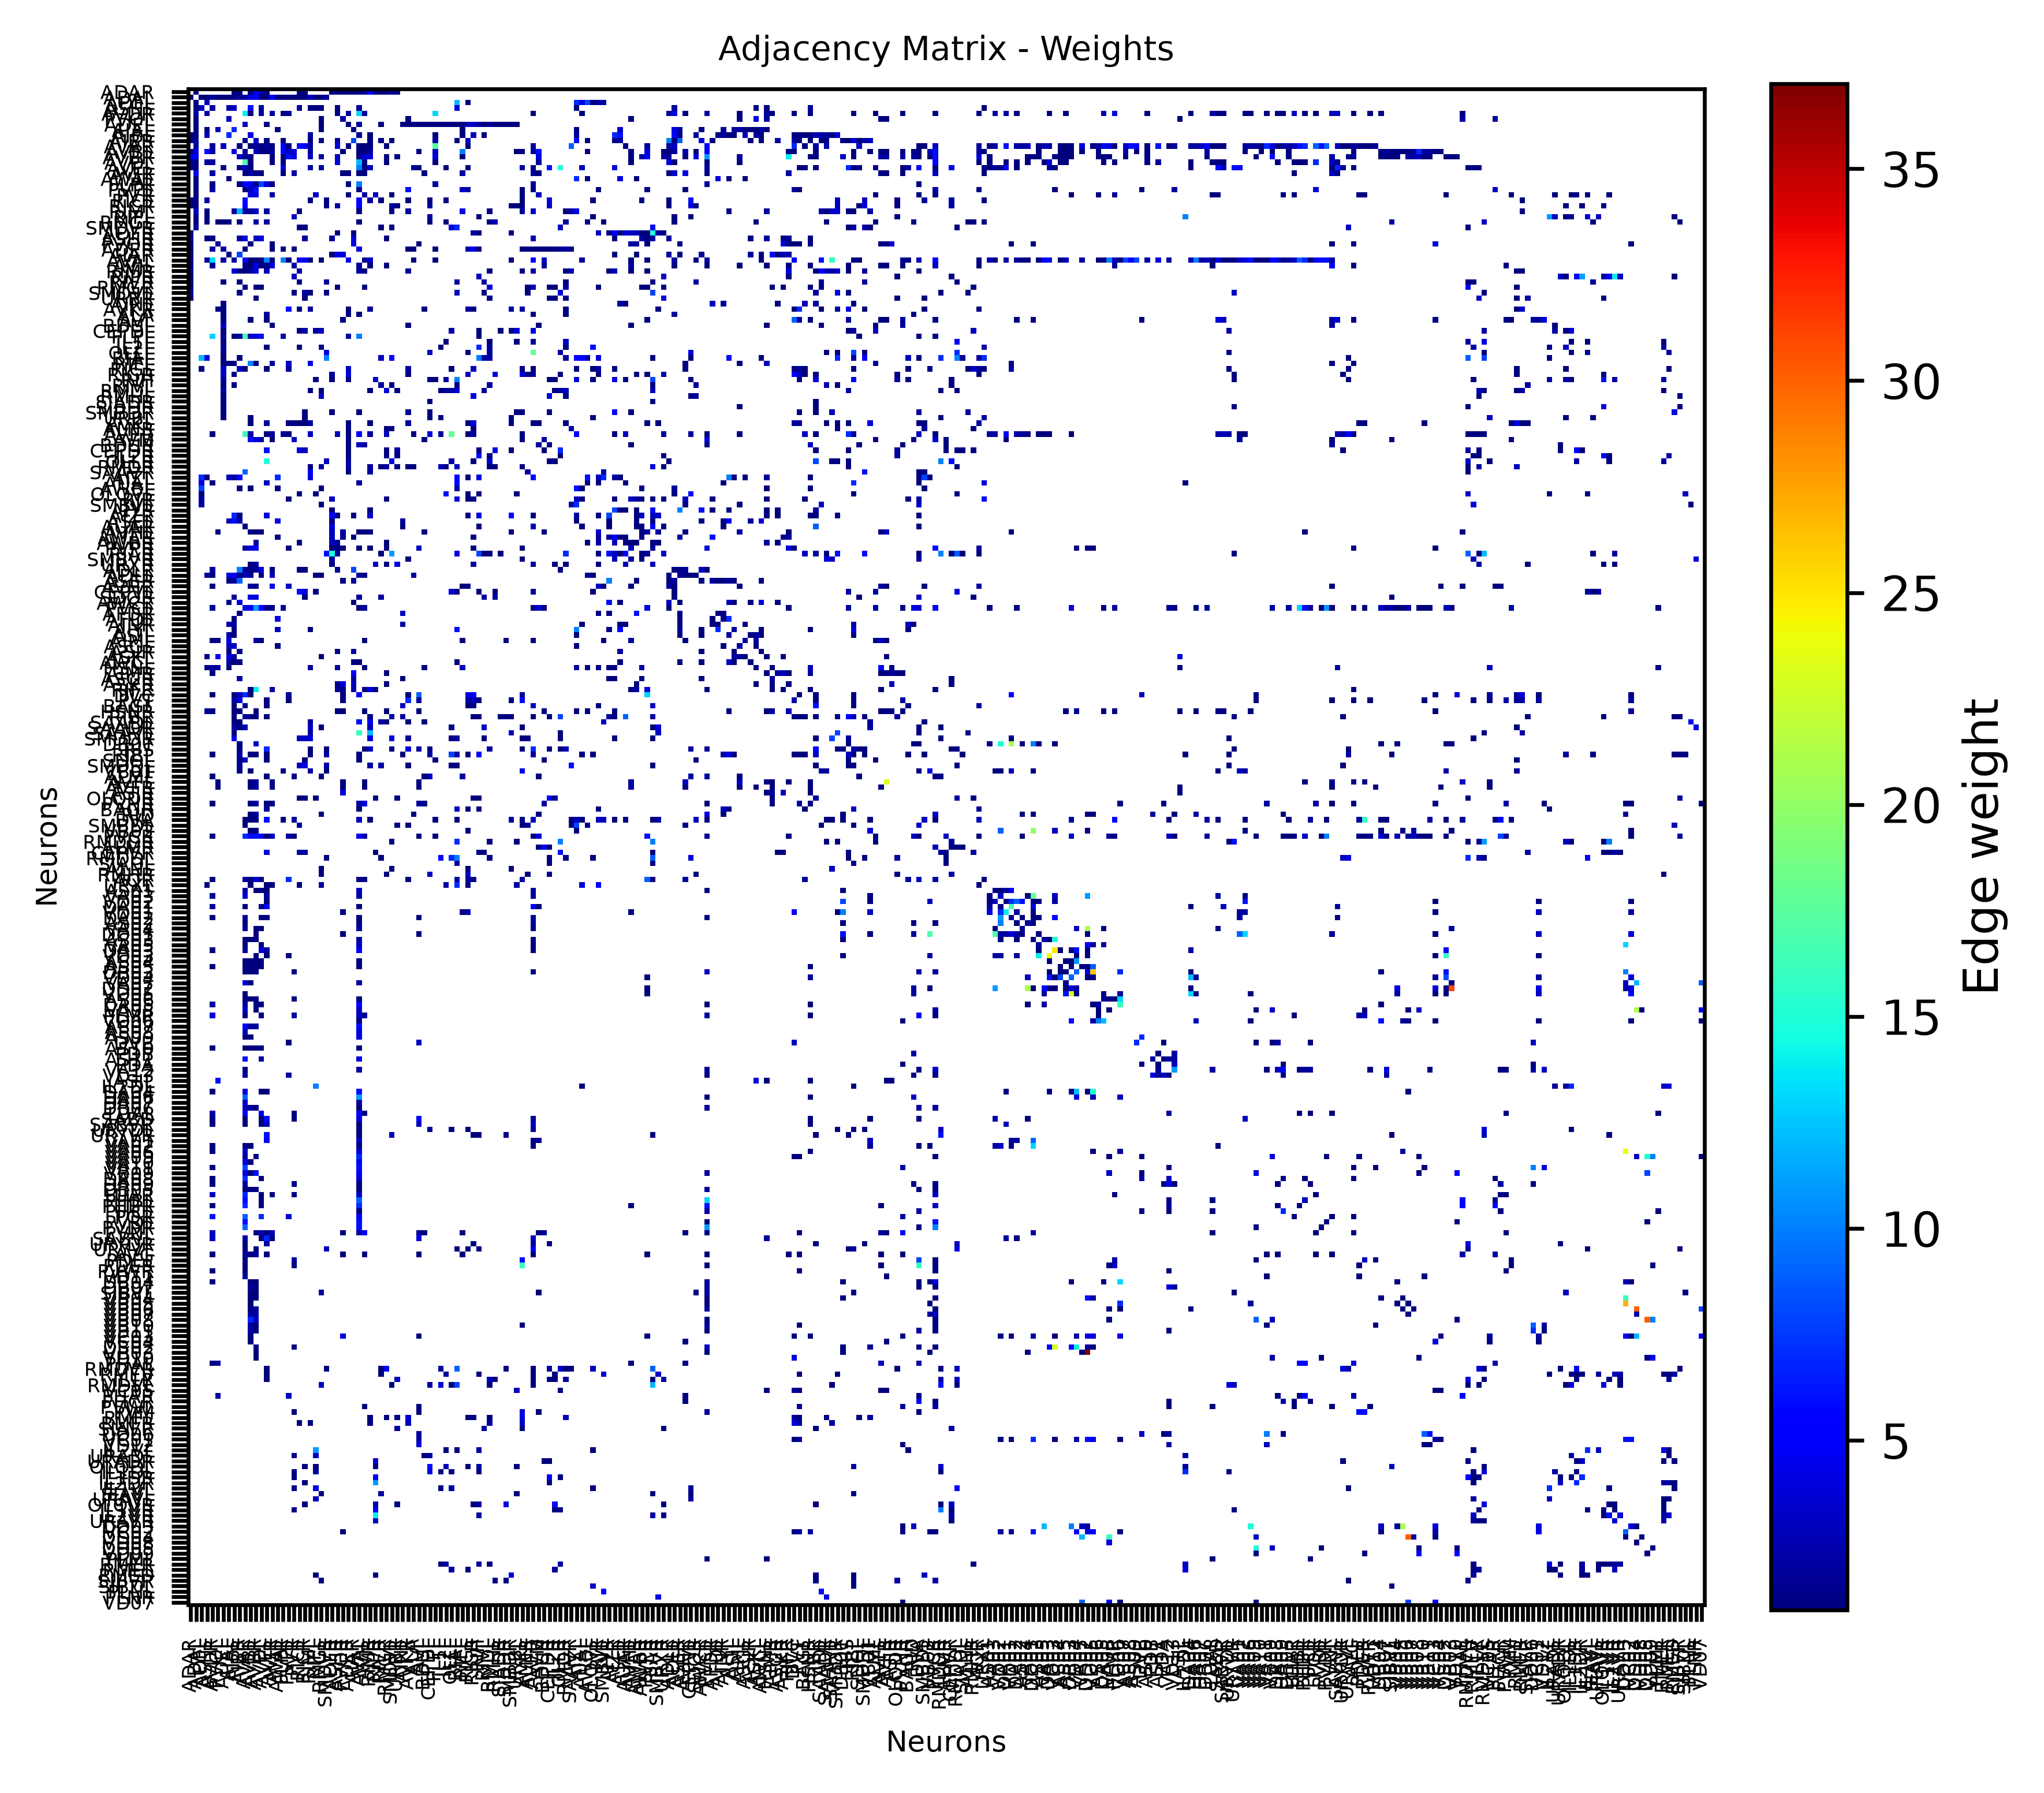

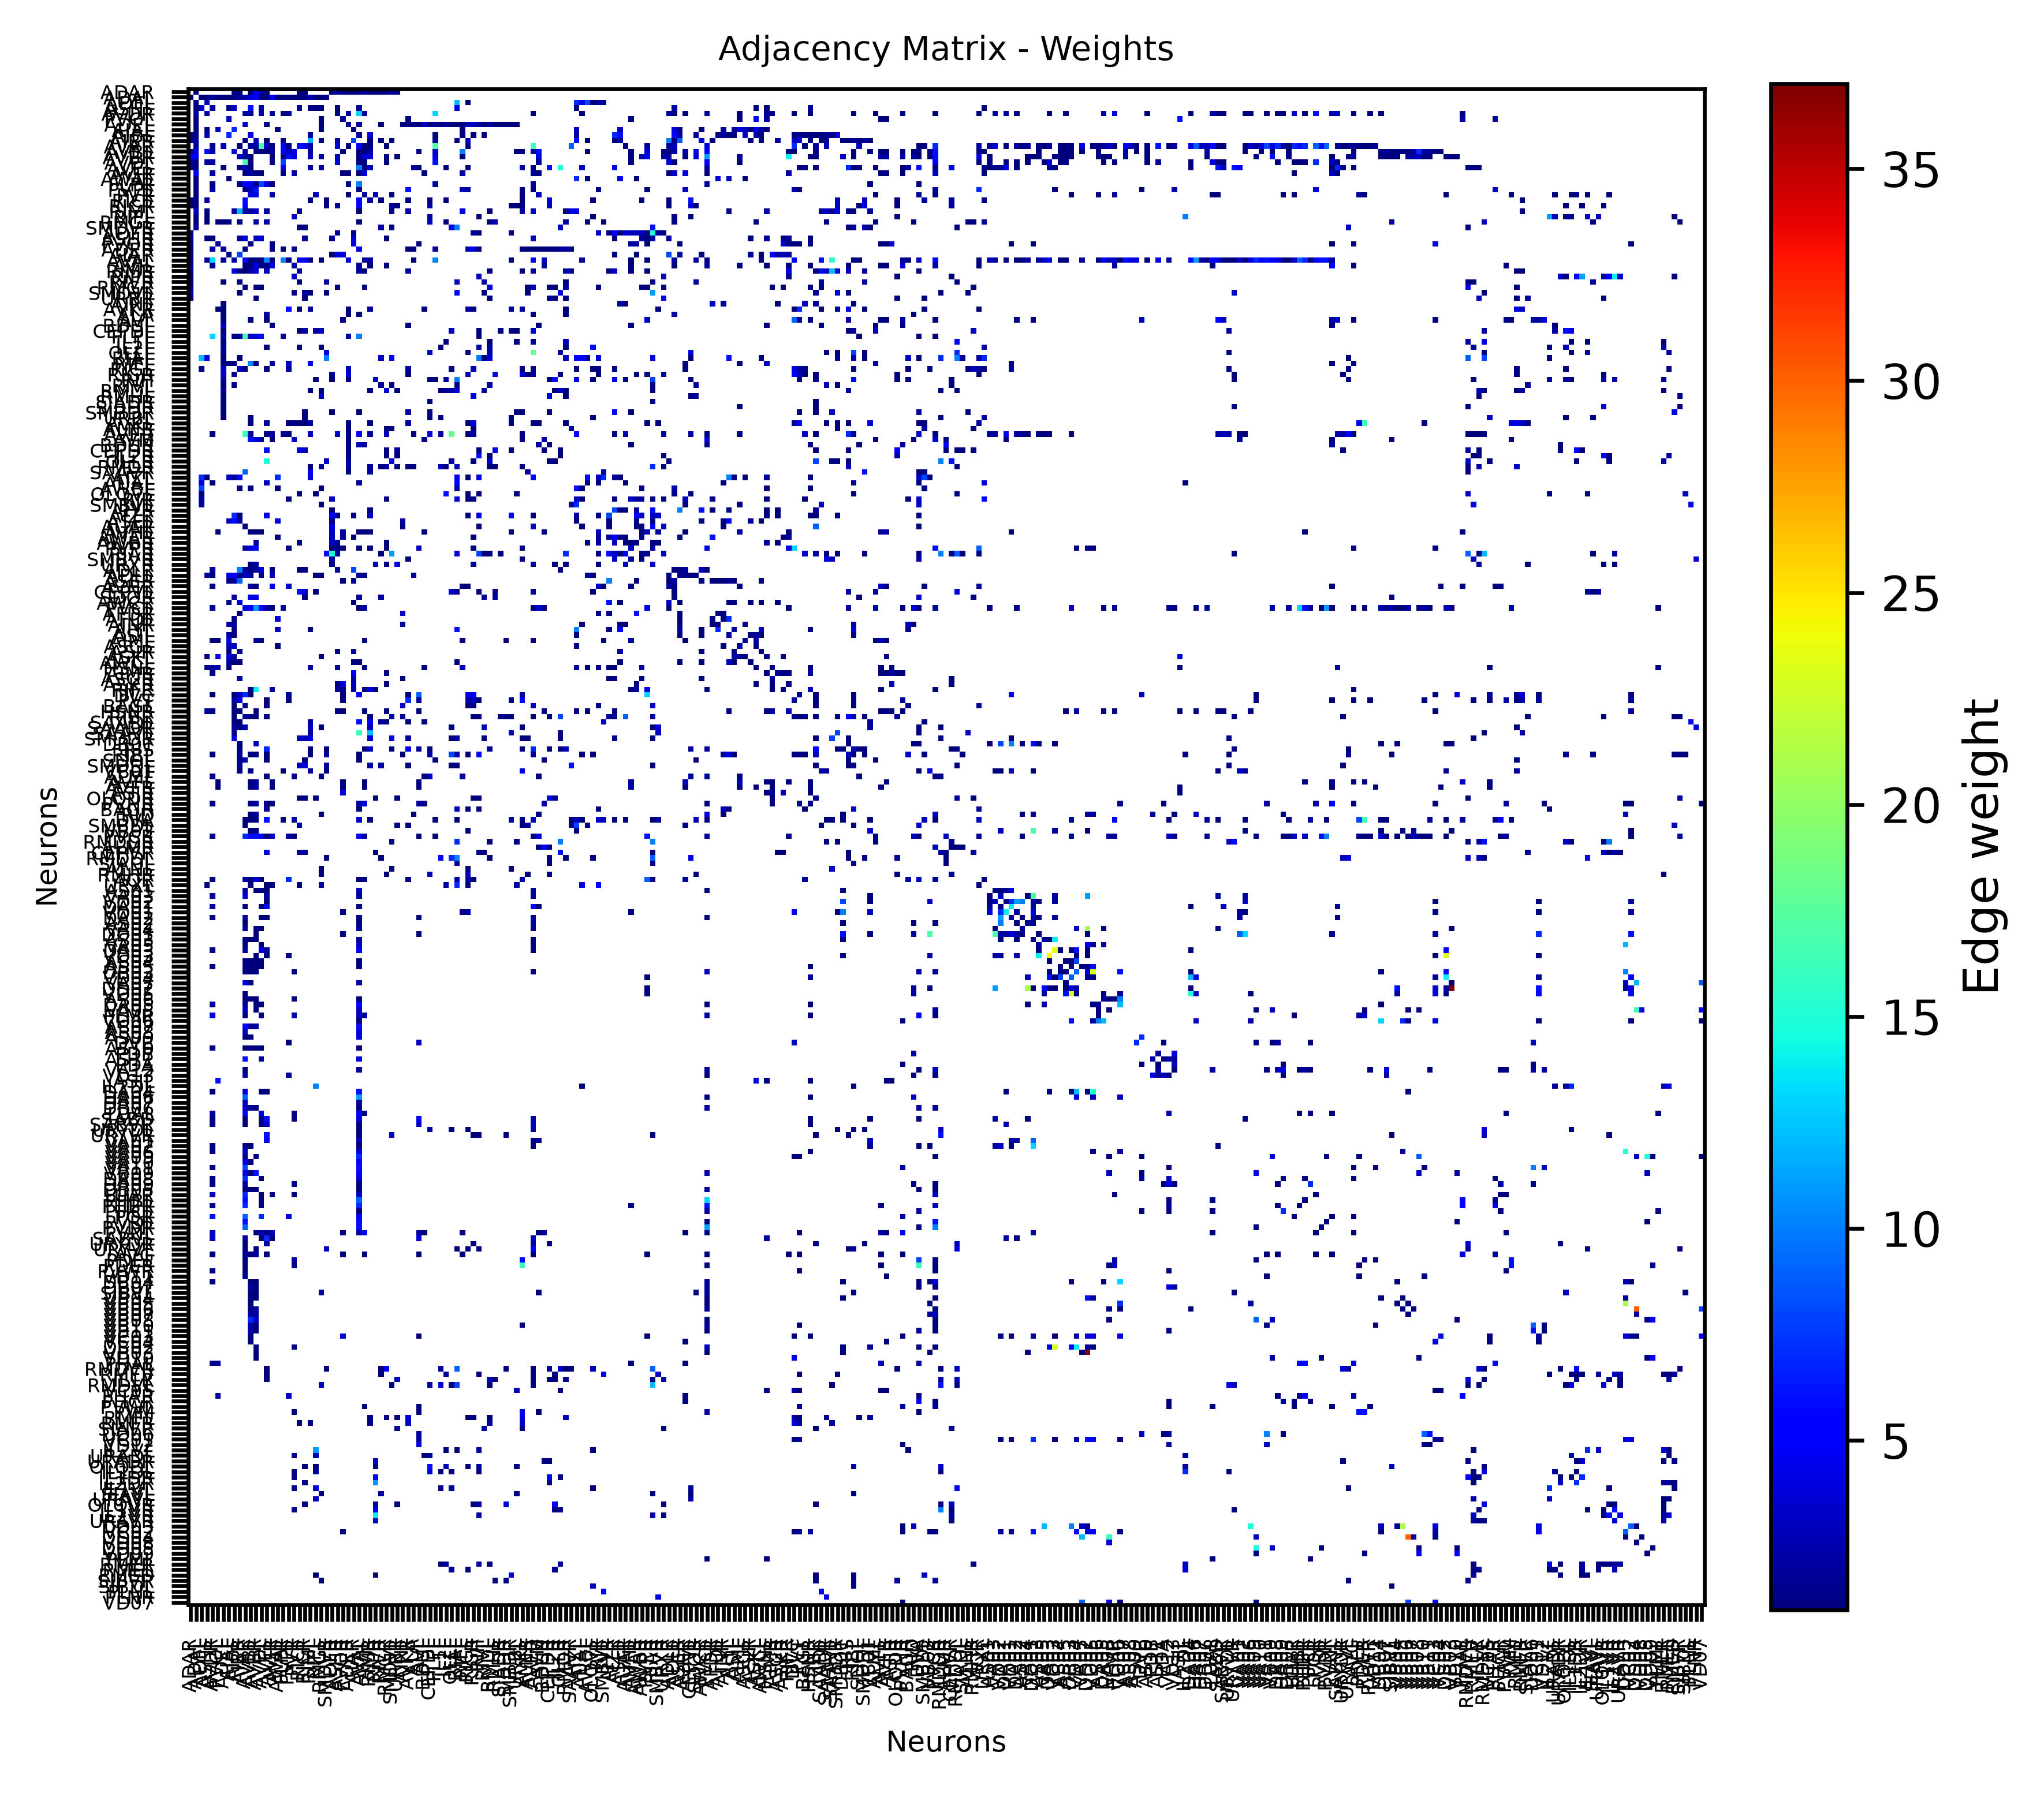

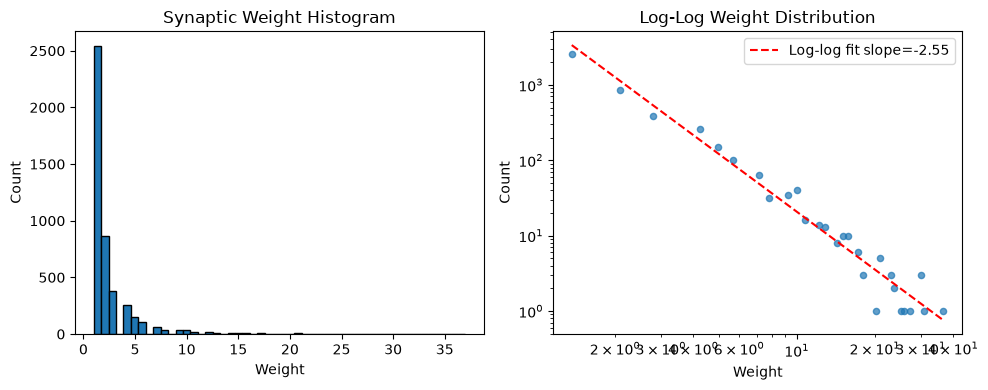


                        NETWORK STATISTICS                        
  Number of neurons:                                       279
  Total number of connections:                           4,577

------------------------------------------------------------------
  DEGREE STATISTICS
------------------------------------------------------------------
  Average in-degree:                                     16.41
  Average out-degree:                                    16.41

------------------------------------------------------------------
  PATH LENGTH AND REACHABILITY
------------------------------------------------------------------
  Average directed shortest path length:                  2.44
  Reachability:                                         100.00 %

------------------------------------------------------------------
  CLUSTERING AND SMALL-WORLDNESS
------------------------------------------------------------------
  Average clustering coefficient:                         0.34


In [31]:
#plotting a adjacency matrix 
plot_adjacency_matrix(G_dir,cmap='jet',sort_nodes=False,figsize=(6,6))

#the undirected graph would look like this: 
G_und = G_dir.to_undirected()
plot_adjacency_matrix(G_und,cmap='jet',sort_nodes=False,figsize=(6,6))

plot_weight_distribution(G_dir, bins=50, fit_powerlaw=True)
stats_elegans = basic_stats(G_dir,random_method="config_preserving") #There is "config_preserving" and "erdos_renyi"


# C8 Let's compute the rich club

We compute the rich club coefficient $\phi$ for all degrees (k) 

$$\phi(k) = \frac{2E_{>k}}{N_{>k}(N_{>k}-1)}$$

we determine if a rich club candidate neuron is signficiant if: $ \phi(real) >  \phi(rand)  + stdev(\phi(rand) ) $

In the Towlson et al., the degree of the richclub was determined as the lowest degree that satisfied   $ \phi(k) > \phi(rand) + 3\sigma $
which happened to be 44. 

Note that our rich club is in good agreement with Towlson et al., however, due to differences in cleaning up the connectome data and how often stringently we run the random networks the standard deviation in the rich club coefficient in the random networks is higher. 

In [ ]:
# ======== COMPUTE RICH-CLUB ========
rc_real, rc_rand_avg, rc_rand_std, rc_norm =  rich_club(G_dir, method="config_preserving",n_rand=10)

# Convert to undirected and get degrees
G_und = G_dir.to_undirected()
degrees = dict(G_und.degree())


# ======== DETERMINE RICH-CLUB THRESHOLD ========
k_vals = list(rc_real.keys())
significant_k = [k for k in k_vals if rc_real[k] > rc_rand_avg[k] + rc_rand_std[k]]

if not significant_k:
    print("No significant rich-club degree found")
    k_rich = None
    rich_club_neurons = []
else:
    k_rich = 44 # This is the value from the paper............
    rich_club_neurons = [n for n, d in degrees.items() if d >= k_rich]
    print(f"Rich-club threshold degree: {k_rich}")
    print(f"Number of neurons in rich club: {len(rich_club_neurons)}")
    print("Rich-club neurons:", rich_club_neurons)

plot_rich_club(rc_real,rc_rand_avg,rc_rand_std,rc_norm,k_vals,k_rich)


## Teacher cell 
### Why is the Rich Club at higher degrees not significant?

In [ ]:
rc_real, rc_rand_avg, rc_rand_std, rc_norm =  rich_club(G_dir, method="config_preserving",n_rand=10,plot_rand_stats=True)

# Teacher cell
visualizing different randomization regimes. 

The randomization method really matters. Different types of randomization preserve different network properties:

* Weight-preserving randomization
* Degree-preserving randomization
* Erdős–Rényi random networks

Depending on the research question, the appropriate randomization method needs to be chosen carefully. Some randomization methods may not be sufficiently conservative, while others may be overly conservative for the question at hand.

* Applying Erdős–Rényi networks to test for the rich-club effect may not be conservative enough, because they do not preserve the degree distribution of the original network. Consequently, differences in rich-club organization may reflect differences in the degree distribution rather than genuine rich-club structure.

* Applying degree-preserving randomization when calculating the SWC may be too conservative, because, particularly in such a small network, the probability of generating networks with wiring patterns similar to those of the original network may be relatively high.

### Note that, in their classical formulation, Erdős–Rényi random networks are typically undirected (as in the Rich Club example below). Here, however, for teaching purposes, we use an implementation that also supports directed networks.

In [ ]:
g_preserved = randomize_graph(G_bio,method="config_preserving",n_type="directed")
g_erdos = randomize_graph(G_bio,method="erdos_renyi",n_type="directed")

print('#########################################################################')
print("ground truth connectivity:")
plot_network(G_bio,positions=positions,show_legend=False)
print('#########################################################################')
print("Randomized, with preserved degrees:")
plot_network(g_preserved,positions=positions,show_legend=False)
print('#########################################################################')
print("Erdos Renyi:")
plot_network(g_erdos,positions=positions,show_legend=False)

print('#########################################################################')
print("ground truth connectivity:")
_ = basic_stats(G_bio)
print('#########################################################################')
print("Randomized, with preserved degrees:")
_ = basic_stats(g_preserved)
print('#########################################################################')
print("Erdos Renyi:")
_ =  basic_stats(g_erdos)

print('#########################################################################')
print('Weight distributions')
print('#########################################################################')


# Lets compare the distribution of real C. elegans and randomized celegans networks.... 
G_fixed  = directed_erdos_renyi_weighted(G_dir)
G_pres  = randomize_graph(G_dir,method="config_preserving",n_type='directed',weighted=True)

print('fixed-edge erdos-renyi:') #because in erdos renyi, egdes are sampled indepedently it just converges towards the number of edges in the parent network. 
plot_weight_distribution(G_fixed, bins=100, fit_powerlaw=True)
print('degree-preserving:')
plot_weight_distribution(G_pres, bins=100, fit_powerlaw=True)
print('C.eleganas:')
plot_weight_distribution(G_dir, bins=100, fit_powerlaw=True)

plot_adjacency_matrix(G_fixed)
plot_adjacency_matrix(G_pres)
plot_adjacency_matrix(G_dir)





## Teacher Cell let's see how these random networks diverge from the real ones: 
We are calculating graph metrics for the real C. elegans , the configuration-preserved randomized, and the Erdos-Renyi ntwrkx

In [ ]:
#Erdos-Renyi as the base of comparison ========================================

avg_degree_real = np.mean([d for n, d in G_und.degree()])
m_real = metric_set(G_und)

G_preserved = randomize_graph(G_und, method="config_preserving")
avg_degree_preserved = np.mean([d for n, d in G_preserved.degree()])
m_preserved = metric_set(G_preserved)

G_er = randomize_graph(G_und, method="erdos_renyi")
avg_degree_er = np.mean([d for n, d in G_er.degree()])
m_er = metric_set(G_er)
labels = ['real','configuration_preserving', 'erdos_renyi']

for i in m_er.keys():
    fig, ax = plt.subplots(figsize=(6,6))
    ax.set_ylabel(i)
    ax.bar(range(3),[m_real[i],m_preserved[i],m_er[i]])
    ax.set_xticks(range(3))
    ax.set_xticklabels(labels)
    plt.show()


## C9 Let's see how computing the random reference netorks influences the rich club detection. 

In [ ]:
rc_real, rc_rand_avg, rc_rand_std, rc_norm = rich_club(G_dir, method="erdos_renyi",n_rand=10)
plot_rich_club(rc_real,rc_rand_avg,rc_rand_std,rc_norm,k_vals,k_rich)


## C10 Let us look at the connectivity statistics of the network 
* Betweeness
* Degree
* Nodal efficiency
* Participation

In [ ]:
#BETWEENNESS 
G = G_und

degree_dict = dict(G.degree()) # puts all the degrees into a dict. 
betweenness = nx.betweenness_centrality(G, normalized=True)
print(betweenness['AIAL'])
print(betweenness['AVAL'])


## C11 Participation coefficient

In [ ]:
communities = list(community.greedy_modularity_communities(G))
modules = {}
for i, com in enumerate(communities):
    for node in com:
        modules[node] = i
participation = participation_coefficient(G, modules)
print(participation['AIAL']) # Rich-club-ish neurons (not included, but similar)
print(participation['AVAL']) # Actual Rich Club member


## C12 Nodal efficiency

In [ ]:
nodal_eff = nodal_efficiency(G)
print(nodal_eff['AIAL'])
print(nodal_eff['AVAL'])

## C13 Determining Rich Club, Periphery, and Whole Network

In [ ]:
# ======== RICH CLUB CLASSIFICATION ==========================================
#back up richclub from the paper (for comparison)
richclub_nodes_paper = ['AVDR',
 'AVAR',
 'AVBL',
 'AVBR',
 'AVDL',
 'AVEL',
 'AVAL',
 'AVER',
 'PVCL',
 'DVA',
 'PVCR']

threshold = 44
richclub_nodes = [n for n, d in degree_dict.items() if d >= threshold]
labels = {n: ("Rich club" if n in richclub_nodes else "Periphery") for n in G.nodes()} # CONSTRUCTING LABELS 

# ======== ASSEMBLE DATAFRAME =================================================
df = pd.DataFrame({
    "neuron": list(G.nodes()),
    "degree": [degree_dict[n] for n in G.nodes()],
    "betweenness": [betweenness[n] for n in G.nodes()],
    "nodal_eff": [nodal_eff[n] for n in G.nodes()],
    "participation": [participation[n] for n in G.nodes()],
    "group": [labels[n] for n in G.nodes()]  # THIS LABELS THEM EITHER as RC or PRERIPHERY
})

# Add "Whole network" group by duplicating rows
df_whole = df.copy()
df_whole["group"] = "Whole network"
df_all = pd.concat([df, df_whole], ignore_index=True)
print(df_all)


## C14 Plotting the coefficients for:
* Rich club
* periphery 
* whole network 

In [ ]:
# ======== PLOTS ==============================================================
metrics = ["degree", "betweenness", "nodal_eff", "participation"]
labels = ["Degree","Betweenness", "Nodal efficiency", "Participation"]

for m,l in zip(metrics,labels):
    plt.figure(figsize=(6,5))
    sns.boxplot(
        data=df_all,
        x="group", y=m,
        hue="group",
        order=["Rich club", "Periphery", "Whole network"],
        palette=["#F72585", "#7209B7", "#3A0CA3"], #["red", "blue", "gray"],
        legend=False
        )
    sns.stripplot(data=df_all, x="group", y=m, order=["Rich club","Periphery","Whole network"],
                  color="k", size=3, jitter=True, alpha=0.6)
    plt.ylabel(l)
    plt.title(l)
    plt.tight_layout()
    plt.show()

## Graphics for the lecture

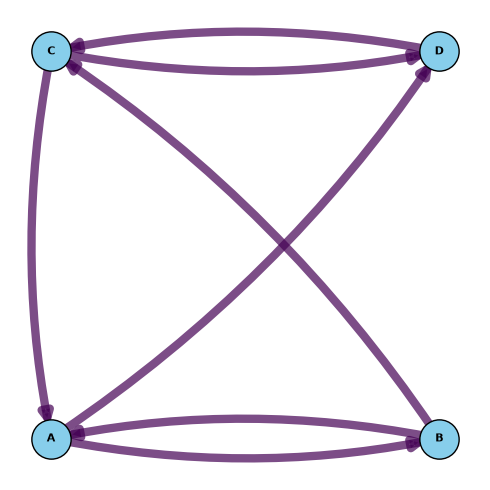

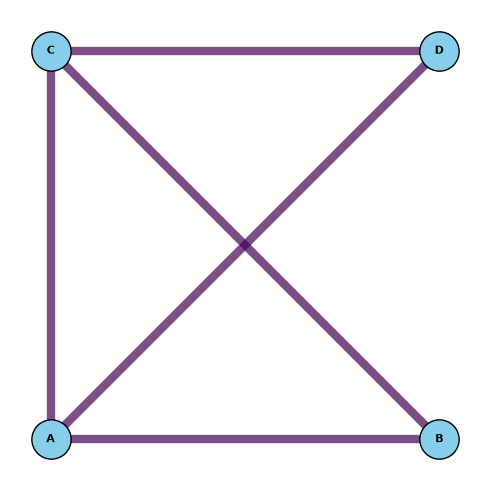

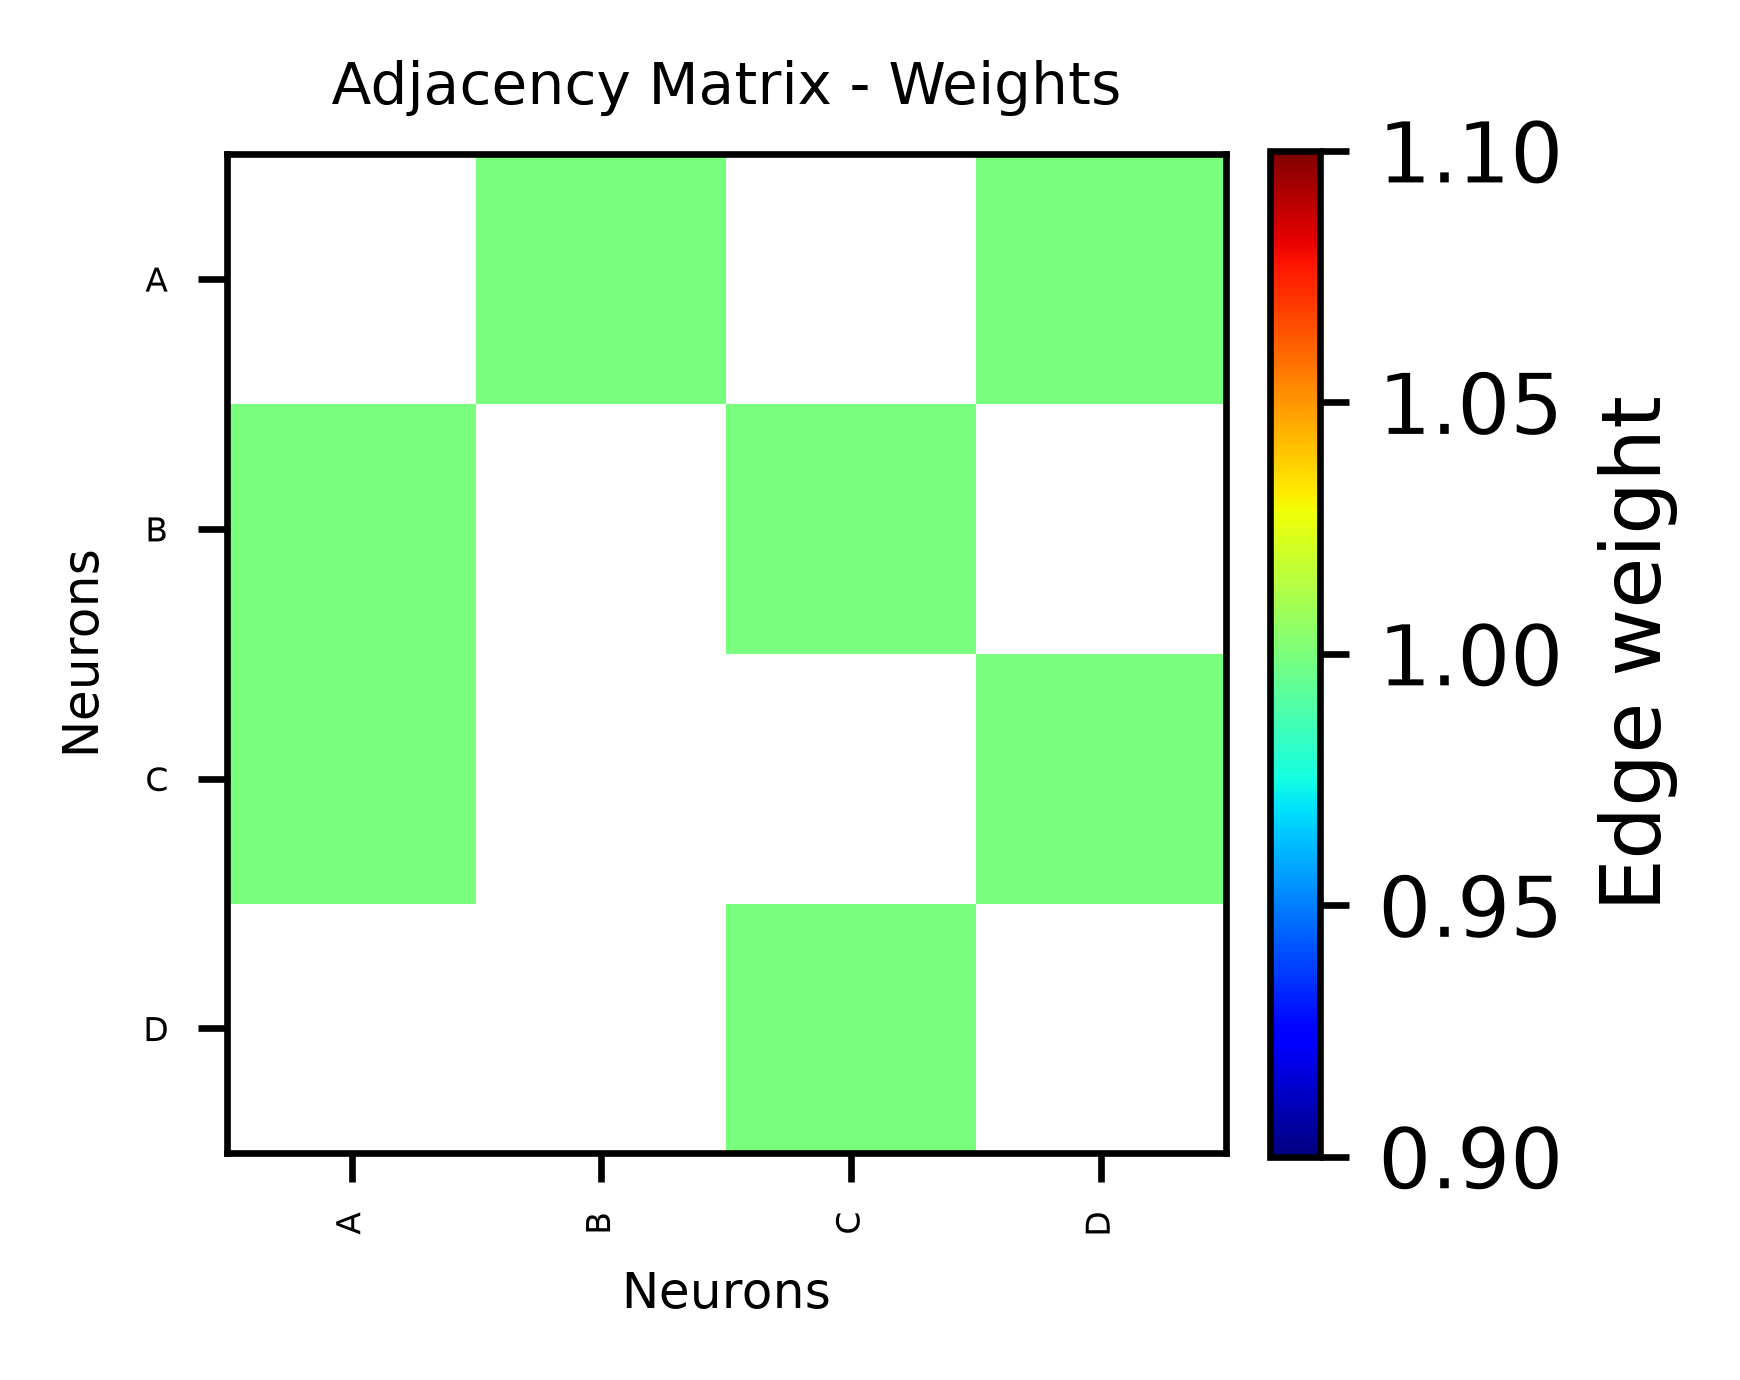

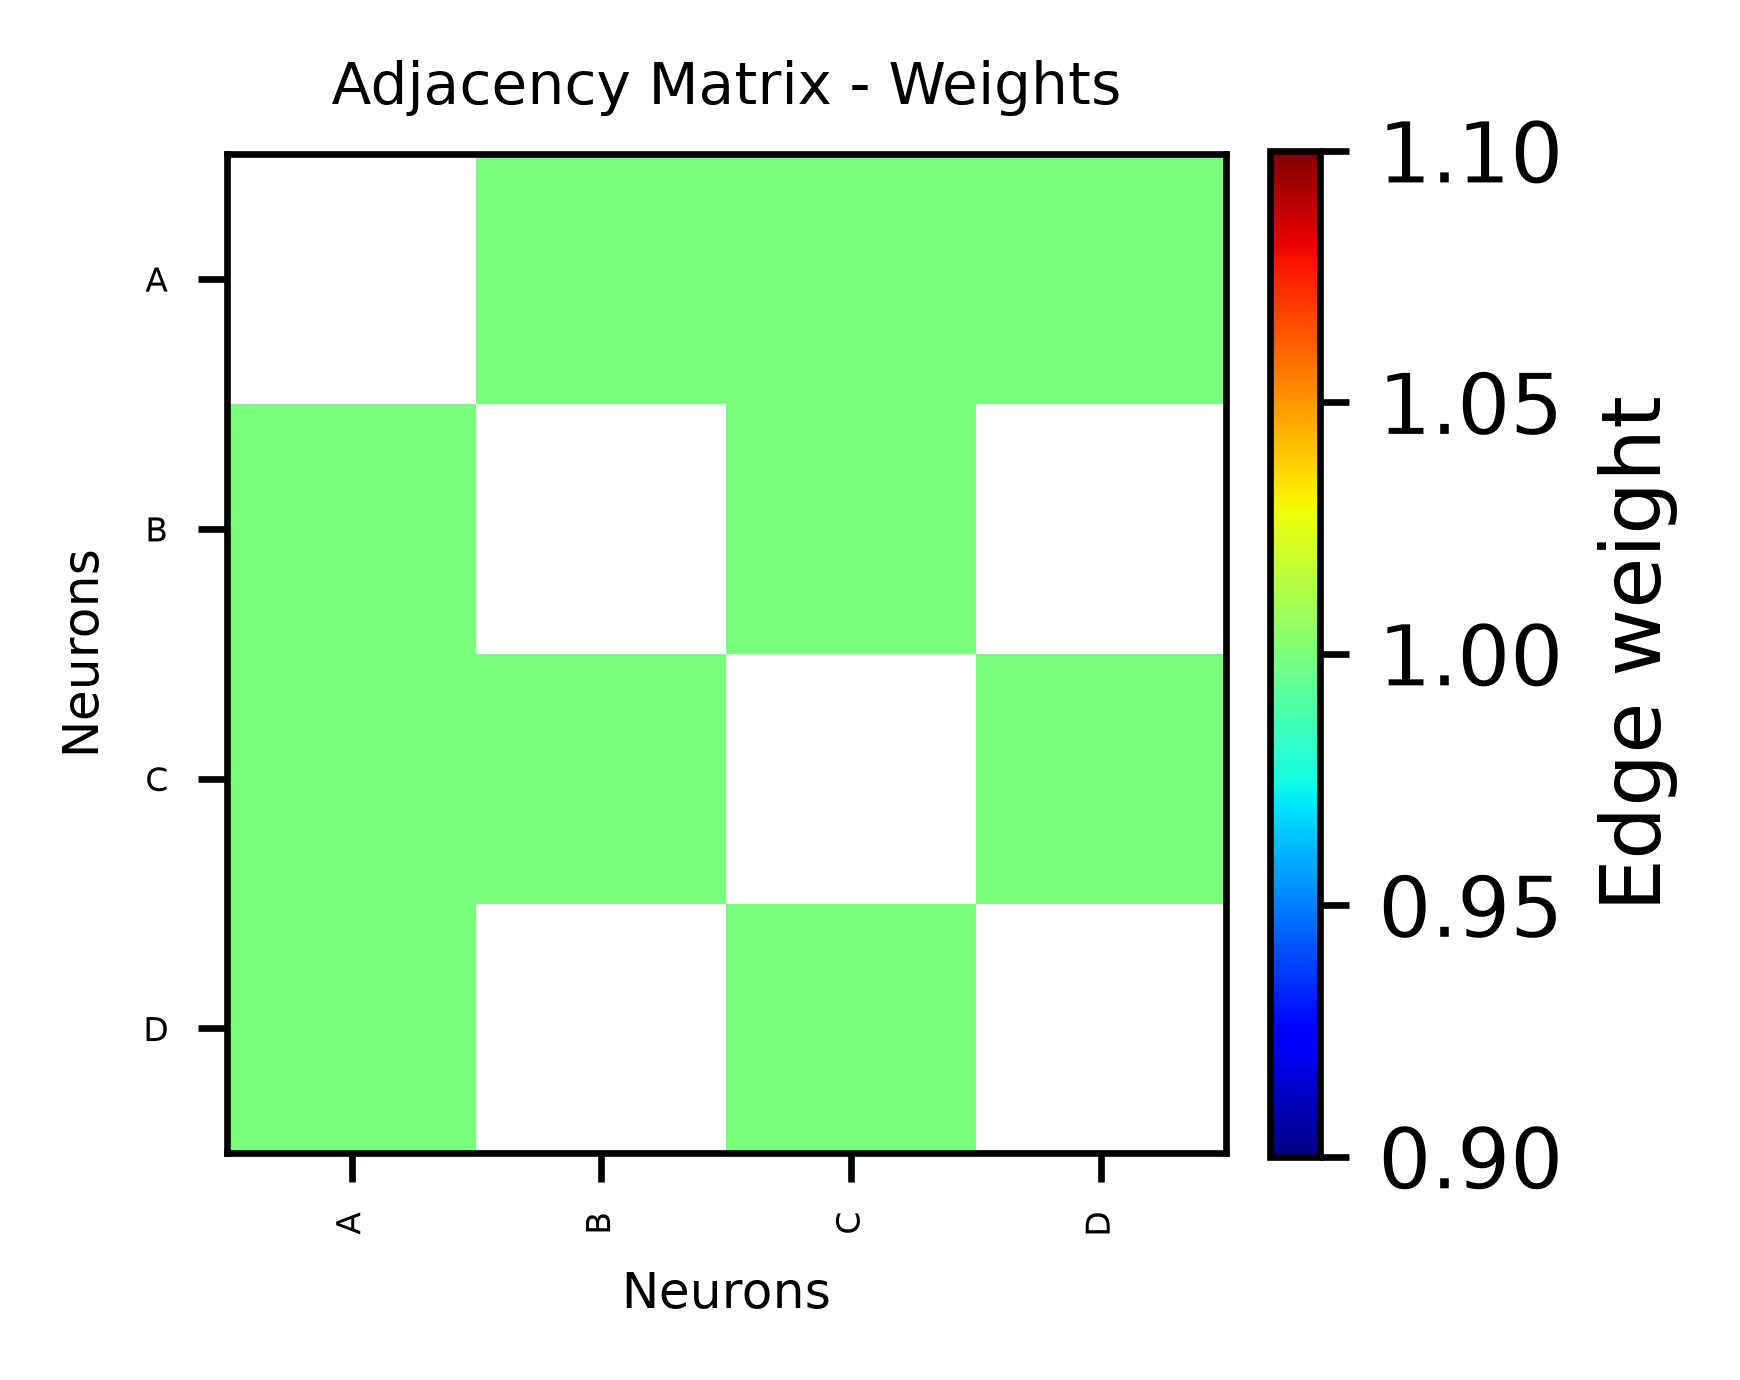

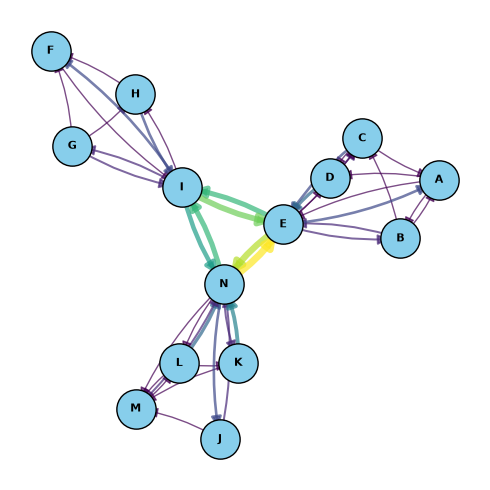

/home/wormulon/models/unito_computational_neuroscience/connectomics_i/code/connectomics_functions.py:1218: UserWarning: 

The arrowstyle keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(
/home/wormulon/models/unito_computational_neuroscience/connectomics_i/code/connectomics_functions.py:1218: UserWarning: 

The arrowsize keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(
/home/wormulon/models/unito_computational_neuroscience/connectomics_i/code/connectomics_functions.py:1218: UserWarning: 

The connectionstyle keyword argument is not a

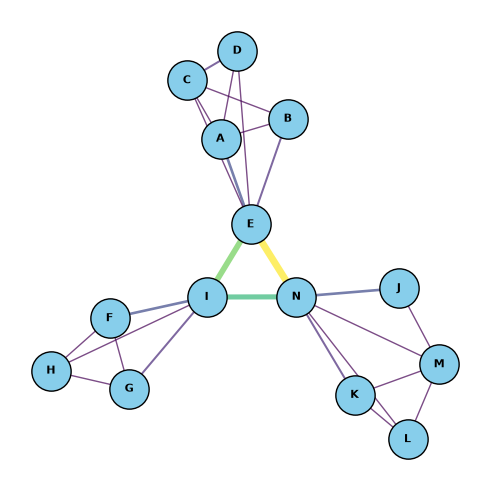

In [28]:
               #   A   B   C   D    E   F  G   H   I   J   K   L   M   N

A_xxxx = np.array([[0., 1., 0., 1.,],
                   [1., 0., 1., 0.,],
                   [1., 0., 0., 1.,],
                   [0., 0., 1., 0.,]])
pos = { 0:[0,0],
                1:[1,0],
                2:[0,1],
                3:[1,1]}
pos = { "A":[0,0],
                "B":[0.5,0],
                "C":[0,0.5],
                "D":[0.5,0.5]}

settings = {
        "node_size": 800,
        "node_color": "skyblue",
        "node_edgecolor": "black",
        "node_linewidth": 1,
        "node_alpha": 1.0,

        "edge_alpha": 0.7,
        "edge_curvature": 0.1,
        "edge_style": "solid",
        "arrow_size": 15,
        "arrow_style": "-|>",

        "edge_color_mode": "weight",
        "edge_color": "gray",

        "label_font_size": 8,
        "label_font_color": "black",
        "label_font_weight": "bold",

        "title": "",
        "title_font_size": 24
    }

G_xxxx = nx.from_numpy_array(A_xxxx, create_using=nx.DiGraph)
G_xxxx = nx.relabel_nodes(G_xxxx, {0:"A",1:"B",2:"C",3:"D",})
G_xxxx_u = G_xxxx.to_undirected()
G_xxxx_u = nx.relabel_nodes(G_xxxx_u, {0:"A",1:"B",2:"C",3:"D",})
plot_network(G_xxxx,show_legend=False,positions=pos,edge_width_factor=(3, 9),settings=settings)
plot_network(G_xxxx_u,show_legend=False,positions=pos,edge_width_factor=(3, 9),settings=settings)
plot_adjacency_matrix(G_xxxx,sort_nodes=False, figsize=(3,3))
plot_adjacency_matrix(G_xxxx_u,sort_nodes=False, figsize=(3,3))



#The rich club calculation illustration 


                   # A   B   C  D  E  F   G   H   I   J   K   L   M  N 
A_rich = np.array([[0., 1., 0., 1.,1, 0., 0., 0., 0., 0., 0., 0., 0.,0.],#A
                   [1., 0., 1., 0.,2, 0., 0., 0., 0., 0., 0., 0., 0.,0.],#B
                   [1., 0., 0., 1.,3, 0., 0., 0., 0., 0., 0., 0., 0.,0.],#C
                   [0., 0., 2., 0.,4, 0., 0., 0., 0., 0., 0., 0., 0.,0.],#D
                   [3., 2., 1., 1.,0, 0., 0., 0., 7., 0., 0., 0., 0.,9.],#E
                   
                   [0., 0., 0., 0.,0, 0., 0., 0., 1., 0., 0., 0., 0.,0.],#F    
                   [0., 0., 0., 0.,0, 1., 0., 1., 2., 0., 0., 0., 0.,0.],#G
                   [0., 0., 0., 0.,0, 1., 0., 0., 3., 0., 0., 0., 0.,0.],#H
                   [0., 0., 0., 0.,8, 3., 2., 1., 0., 0., 0., 0., 0.,6.],#I

                   [0., 0., 0., 0.,0, 0., 0., 0., 0., 0., 0., 0., 1.,2.],#J
                   [0., 0., 0., 0.,0, 0., 0., 0., 0., 0,  0., 0., 1.,5.],#K      
                   [0., 0., 0., 0.,0, 0., 0., 0., 0., 0,  1., 0., 1.,4.],#L
                   [0., 0., 0., 0.,0, 0., 0., 0., 0., 0., 0., 1., 0.,2.],#M
                   [0., 0., 0., 0.,10, 0., 0., 0., 7., 3., 2., 1., 1.,0.]])#N



G_rich = nx.from_numpy_array(A_rich, create_using=nx.DiGraph)
G_rich = nx.relabel_nodes(G_rich, {0:"A",1:"B",2:"C",3:"D",4:"E",5:"F",6:"G",7:"H",8:"I",9:"J",10:"K",11:"L",12:"M",13:"N"})
G_rich_und = G_rich.to_undirected()
plot_network(G_rich,show_legend=False,edge_width_factor=(1, 5),settings=settings)
plot_network(G_rich_und,show_legend=False,edge_width_factor=(1, 5),settings=settings)
